# Bilgisayarla Görme - Ödev

Bu haftaya kadar işlediklerimizin kod versiyonu (Python + OpenCV).

**Kurulum (Anaconda Prompt):** `pip install opencv-python scikit-image scikit-learn matplotlib pandas`

Hücreleri sırayla çalıştır (`Shift+Enter`). İlk hücredeki `GORSEL_YOLU` değişkenine kendi görselinin adını yaz.

In [1]:
   %pip install opencv-python scikit-image scikit-learn matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


## 0) Kütüphaneler ve görselin yüklenmesi

Görüntü boyutu (yükseklik, genişlik, kanal): (1000, 750, 3)


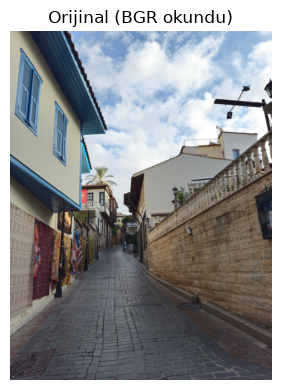

In [2]:
%matplotlib inline
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt

GORSEL_YOLU = "20241116_102307.jpg"   # <-- kendi görselinin yolunu yaz

if os.path.exists(GORSEL_YOLU):
    img_bgr = cv2.imread(GORSEL_YOLU)
else:
    # Görsel bulunamazsa örnek bir görsel kullan
    from skimage import data
    img_bgr = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2BGR)
    print(GORSEL_YOLU, "bulunamadı, örnek görsel kullanılıyor.")

# Telefon fotoğrafı çok büyük olabilir; işlemler hızlı çalışsın diye en uzun kenarı 1000 piksele indir
en_uzun = max(img_bgr.shape[:2])
if en_uzun > 1000:
    oran = 1000 / en_uzun
    img_bgr = cv2.resize(img_bgr, None, fx=oran, fy=oran, interpolation=cv2.INTER_AREA)

def goster(goruntuler, basliklar, satir=1, gri=None):
    """Birden fazla görüntüyü yan yana gösterir. BGR görüntüleri RGB'ye çevirir."""
    n = len(goruntuler)
    sutun = int(np.ceil(n / satir))
    plt.figure(figsize=(4 * sutun, 4 * satir))
    for i, (g, b) in enumerate(zip(goruntuler, basliklar)):
        plt.subplot(satir, sutun, i + 1)
        if g.ndim == 2:
            plt.imshow(g, cmap="gray")
        else:
            plt.imshow(cv2.cvtColor(g, cv2.COLOR_BGR2RGB))
        plt.title(b)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
print("Görüntü boyutu (yükseklik, genişlik, kanal):", img_bgr.shape)
goster([img_bgr], ["Orijinal (BGR okundu)"])

## 1) BGR -> HSV (ve diğer renk uzayı dönüşümleri)

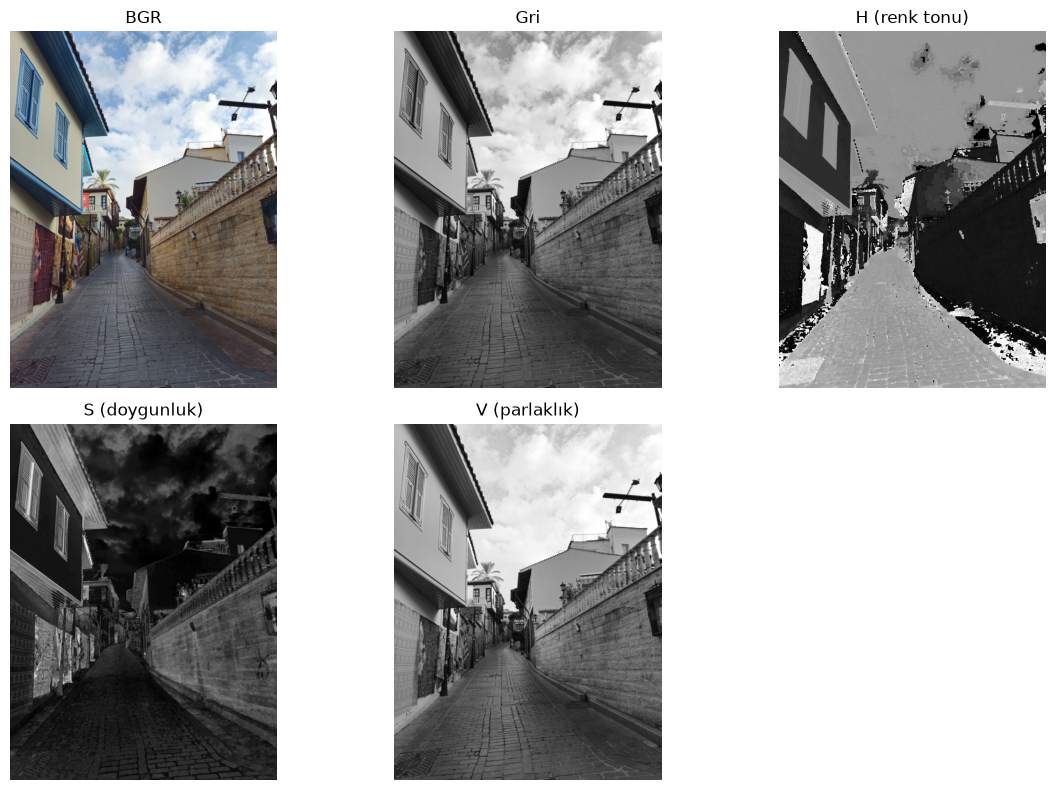

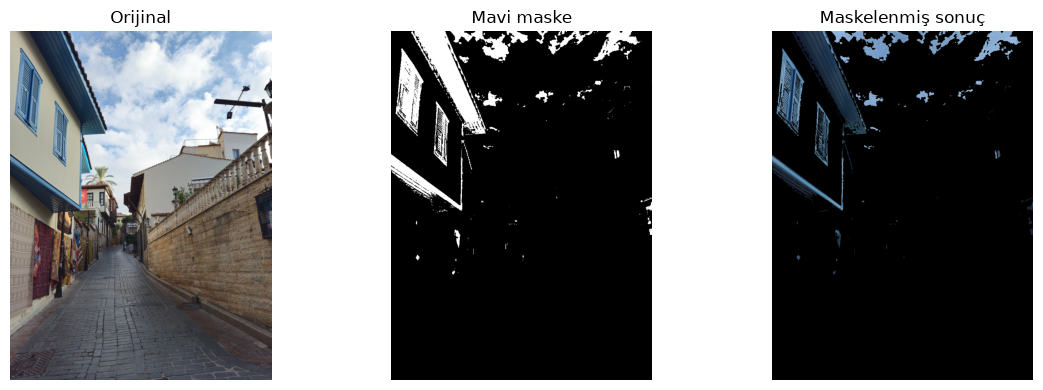

In [3]:
img_hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

h, s, v = cv2.split(img_hsv)
goster([img_bgr, img_gray, h, s, v],
       ["BGR", "Gri", "H (renk tonu)", "S (doygunluk)", "V (parlaklık)"], satir=2)

# HSV ile basit renk maskeleme örneği (mavi tonlar)
alt, ust = np.array([100, 80, 50]), np.array([130, 255, 255])
maske = cv2.inRange(img_hsv, alt, ust)
sonuc = cv2.bitwise_and(img_bgr, img_bgr, mask=maske)
goster([img_bgr, maske, sonuc], ["Orijinal", "Mavi maske", "Maskelenmiş sonuç"])

## 2) Görüntüyü yeniden boyutlandırma

Orijinal: (1000, 750, 3) | Küçük: (500, 375, 3) | Büyük: (2000, 1500, 3) | Sabit: (300, 300, 3)


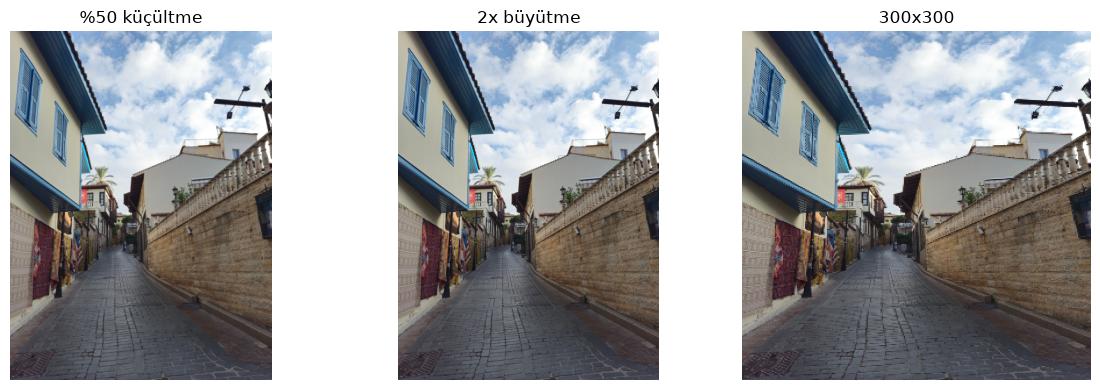

In [4]:
kucuk = cv2.resize(img_bgr, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
buyuk = cv2.resize(img_bgr, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
sabit = cv2.resize(img_bgr, (300, 300))  # sabit boyut (genişlik, yükseklik)

print("Orijinal:", img_bgr.shape, "| Küçük:", kucuk.shape,
      "| Büyük:", buyuk.shape, "| Sabit:", sabit.shape)
goster([kucuk, buyuk, sabit], ["%50 küçültme", "2x büyütme", "300x300"])

## 3) Görüntü iyileştirme - Histogram analizi

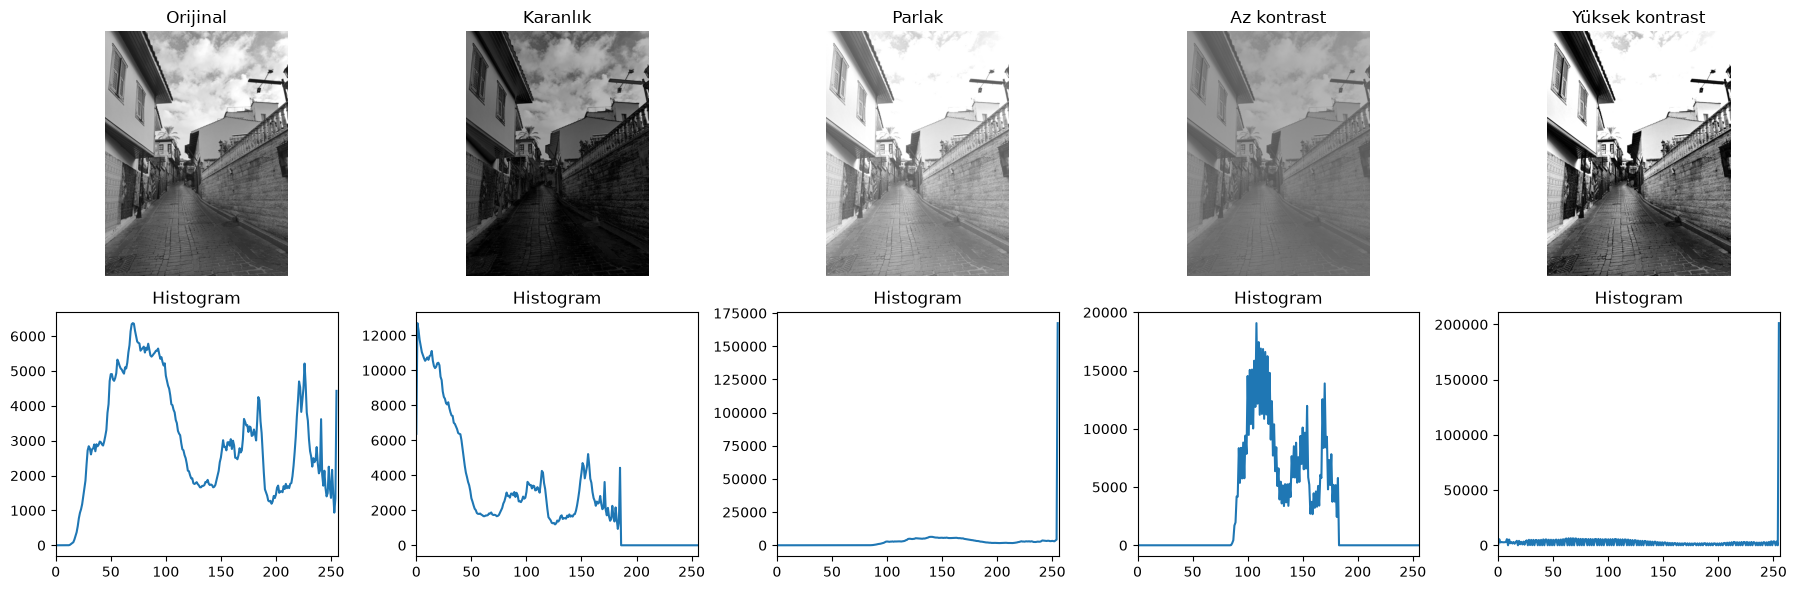

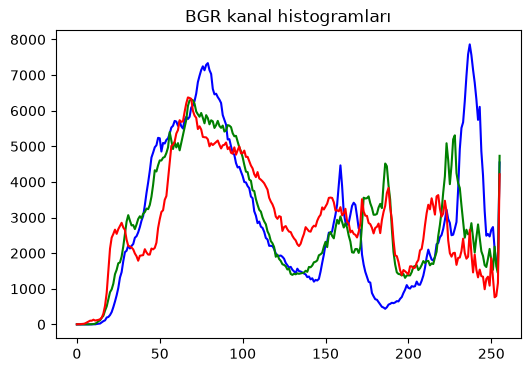

In [5]:
# Karanlık, parlak, az kontrastlı ve yüksek kontrastlı versiyonlar üretelim
karanlik = cv2.convertScaleAbs(img_gray, alpha=1.0, beta=-70)     # karanlık
parlak = cv2.convertScaleAbs(img_gray, alpha=1.0, beta=70)        # parlak
az_kontrast = cv2.convertScaleAbs(img_gray, alpha=0.4, beta=80)   # az kontrast
yuksek_kontrast = cv2.convertScaleAbs(img_gray, alpha=1.8, beta=-60)  # yüksek kontrast

liste = [img_gray, karanlik, parlak, az_kontrast, yuksek_kontrast]
basliklar = ["Orijinal", "Karanlık", "Parlak", "Az kontrast", "Yüksek kontrast"]

plt.figure(figsize=(18, 6))
for i, (g, b) in enumerate(zip(liste, basliklar)):
    plt.subplot(2, 5, i + 1)
    plt.imshow(g, cmap="gray", vmin=0, vmax=255)
    plt.title(b); plt.axis("off")
    plt.subplot(2, 5, i + 6)
    hist = cv2.calcHist([g], [0], None, [256], [0, 256])
    plt.plot(hist); plt.xlim([0, 256])
    plt.title("Histogram")
plt.tight_layout(); plt.show()

# Renkli görüntüde kanal histogramları
plt.figure(figsize=(6, 4))
for i, renk in enumerate(("b", "g", "r")):
    plt.plot(cv2.calcHist([img_bgr], [i], None, [256], [0, 256]), color=renk)
plt.title("BGR kanal histogramları"); plt.show()

## 3b) Görüntü azaltma (gri seviye azaltma) ve Histogram eşitleme

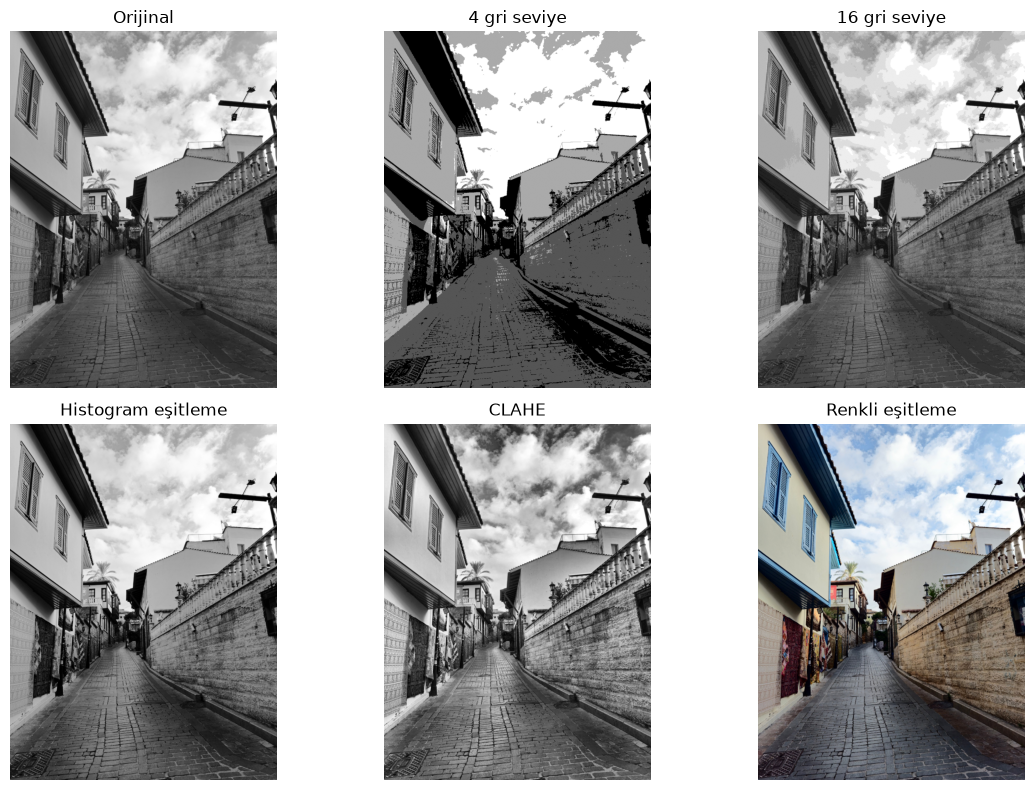

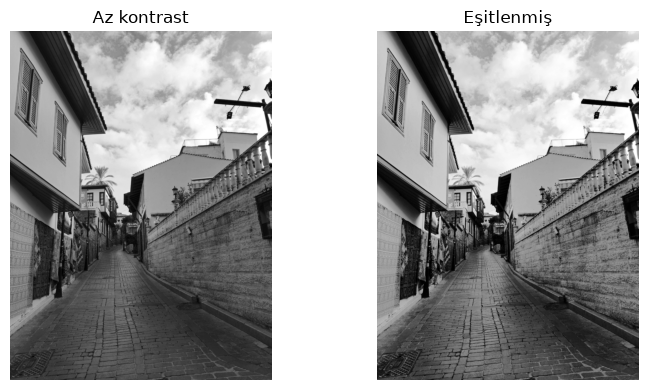

In [6]:
# Gürültü / parlaklık azaltma: gri seviyeyi azalt (quantization)
def gri_seviye_azalt(gri, seviye):
    adim = 256 // seviye
    return (gri // adim) * adim

az4 = gri_seviye_azalt(img_gray, 4)
az16 = gri_seviye_azalt(img_gray, 16)

# Histogram eşitleme (global) ve CLAHE (yerel)
esit = cv2.equalizeHist(img_gray)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(img_gray)

# Renkli görüntüde eşitleme: sadece parlaklık kanalına uygula (YCrCb)
ycrcb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2YCrCb)
ycrcb[:, :, 0] = cv2.equalizeHist(ycrcb[:, :, 0])
renkli_esit = cv2.cvtColor(ycrcb, cv2.COLOR_YCrCb2BGR)

goster([img_gray, az4, az16, esit, clahe, renkli_esit],
       ["Orijinal", "4 gri seviye", "16 gri seviye",
        "Histogram eşitleme", "CLAHE", "Renkli eşitleme"], satir=2)

# Düşük kontrastlı görüntüye eşitleme uygulayınca fark daha net görünür
goster([az_kontrast, cv2.equalizeHist(az_kontrast)],
       ["Az kontrast", "Eşitlenmiş"])

## 4) Konvolüsyon işlemi ve kernel - Kimlik, Blur, Gaussian, Sharpen

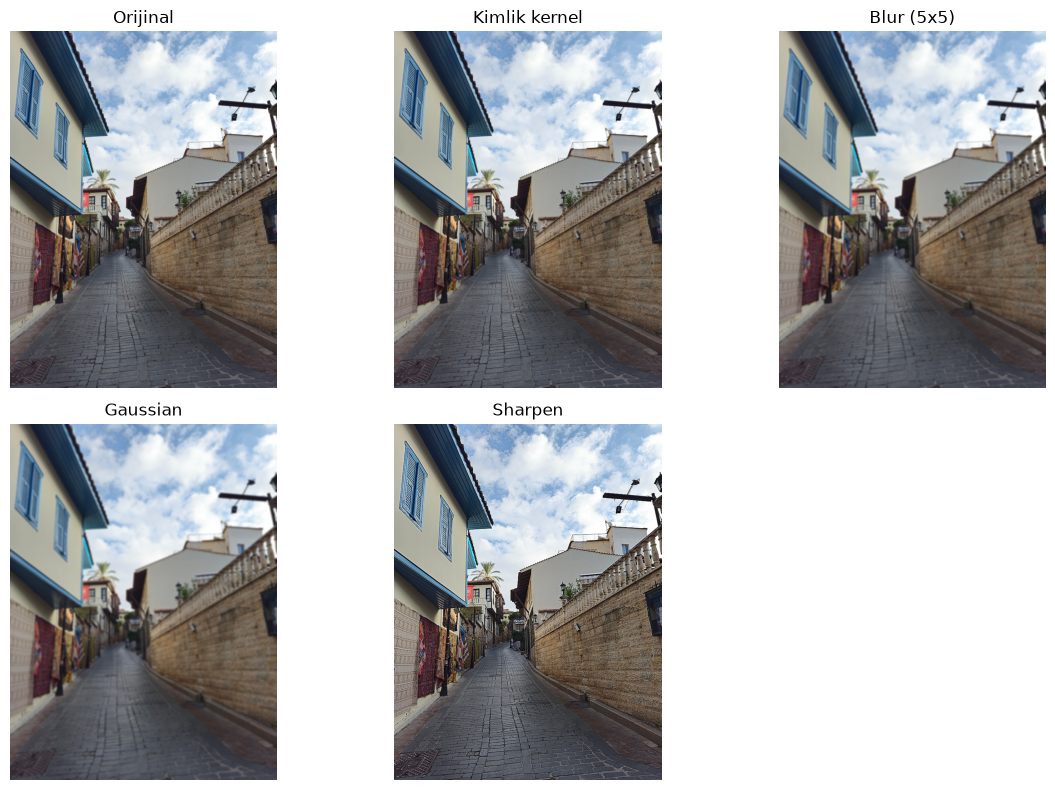

Kimlik kernel orijinalle aynı mı?: True


In [7]:
kernel_kimlik = np.array([[0, 0, 0],
                          [0, 1, 0],
                          [0, 0, 0]], dtype=np.float32)       # görüntüyü değiştirmez
kernel_blur = np.ones((5, 5), np.float32) / 25                # ortalama (box) blur
kernel_sharpen = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]], dtype=np.float32)     # keskinleştirme

kimlik = cv2.filter2D(img_bgr, -1, kernel_kimlik)
blur = cv2.filter2D(img_bgr, -1, kernel_blur)
blur_hazir = cv2.blur(img_bgr, (5, 5))
gauss = cv2.GaussianBlur(img_bgr, (9, 9), sigmaX=2)
sharpen = cv2.filter2D(img_bgr, -1, kernel_sharpen)

goster([img_bgr, kimlik, blur, gauss, sharpen],
       ["Orijinal", "Kimlik kernel", "Blur (5x5)", "Gaussian", "Sharpen"], satir=2)

# Fark kontrolü: kimlik kernel orijinalle aynı mı?
print("Kimlik kernel orijinalle aynı mı?:", np.array_equal(img_bgr, kimlik))

## 5) Edge Detection / Kenar tespiti

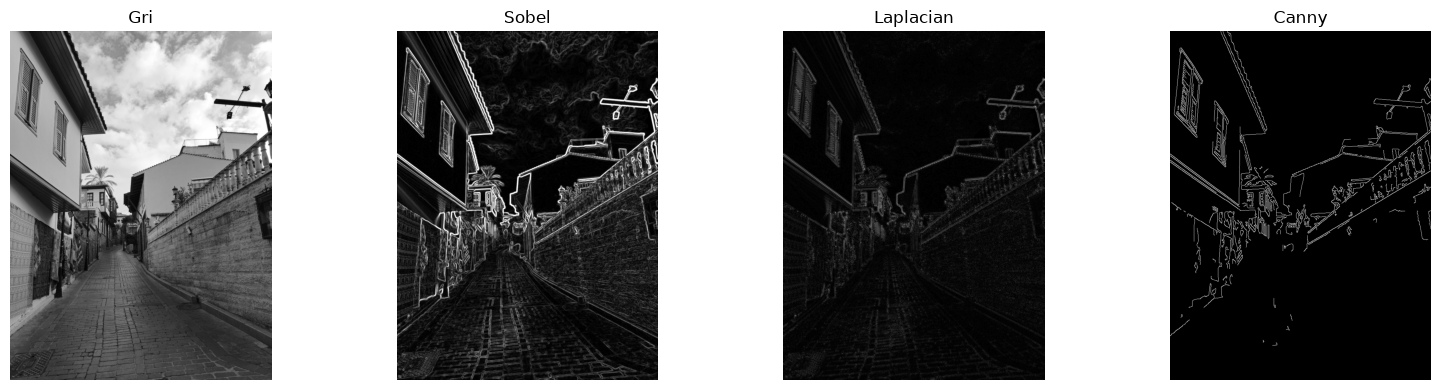

In [8]:
gri_blur = cv2.GaussianBlur(img_gray, (5, 5), 0)

sobel_x = cv2.Sobel(gri_blur, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gri_blur, cv2.CV_64F, 0, 1, ksize=3)
sobel = cv2.convertScaleAbs(cv2.magnitude(sobel_x, sobel_y))
laplacian = cv2.convertScaleAbs(cv2.Laplacian(gri_blur, cv2.CV_64F))
canny = cv2.Canny(gri_blur, 100, 200)

goster([img_gray, sobel, laplacian, canny],
       ["Gri", "Sobel", "Laplacian", "Canny"])

## 6) ROI (Region of Interest - İlgi Bölgesi)

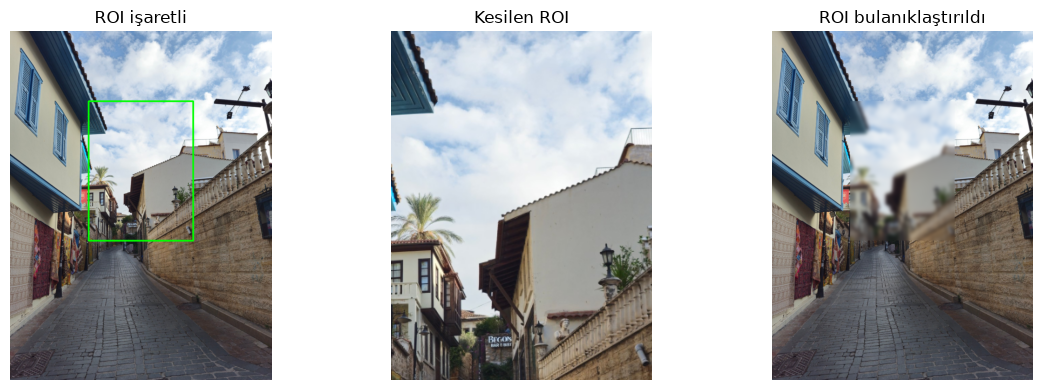

In [9]:
yuk, gen = img_bgr.shape[:2]
y1, y2 = int(yuk * 0.2), int(yuk * 0.6)
x1, x2 = int(gen * 0.3), int(gen * 0.7)

roi = img_bgr[y1:y2, x1:x2].copy()           # kesip al
isaretli = img_bgr.copy()
cv2.rectangle(isaretli, (x1, y1), (x2, y2), (0, 255, 0), 3)

# ROI üzerinde işlem: sadece o bölgeyi griye çevir/bulanıklaştır
roi_islem = img_bgr.copy()
roi_islem[y1:y2, x1:x2] = cv2.GaussianBlur(roi_islem[y1:y2, x1:x2], (33,33), 0)

goster([isaretli, roi, roi_islem],
       ["ROI işaretli", "Kesilen ROI", "ROI bulanıklaştırıldı"])

## 7) Eşikleme / Thresholding (Binary Thresholding dahil)

Otsu'nun bulduğu eşik değeri: 136.0


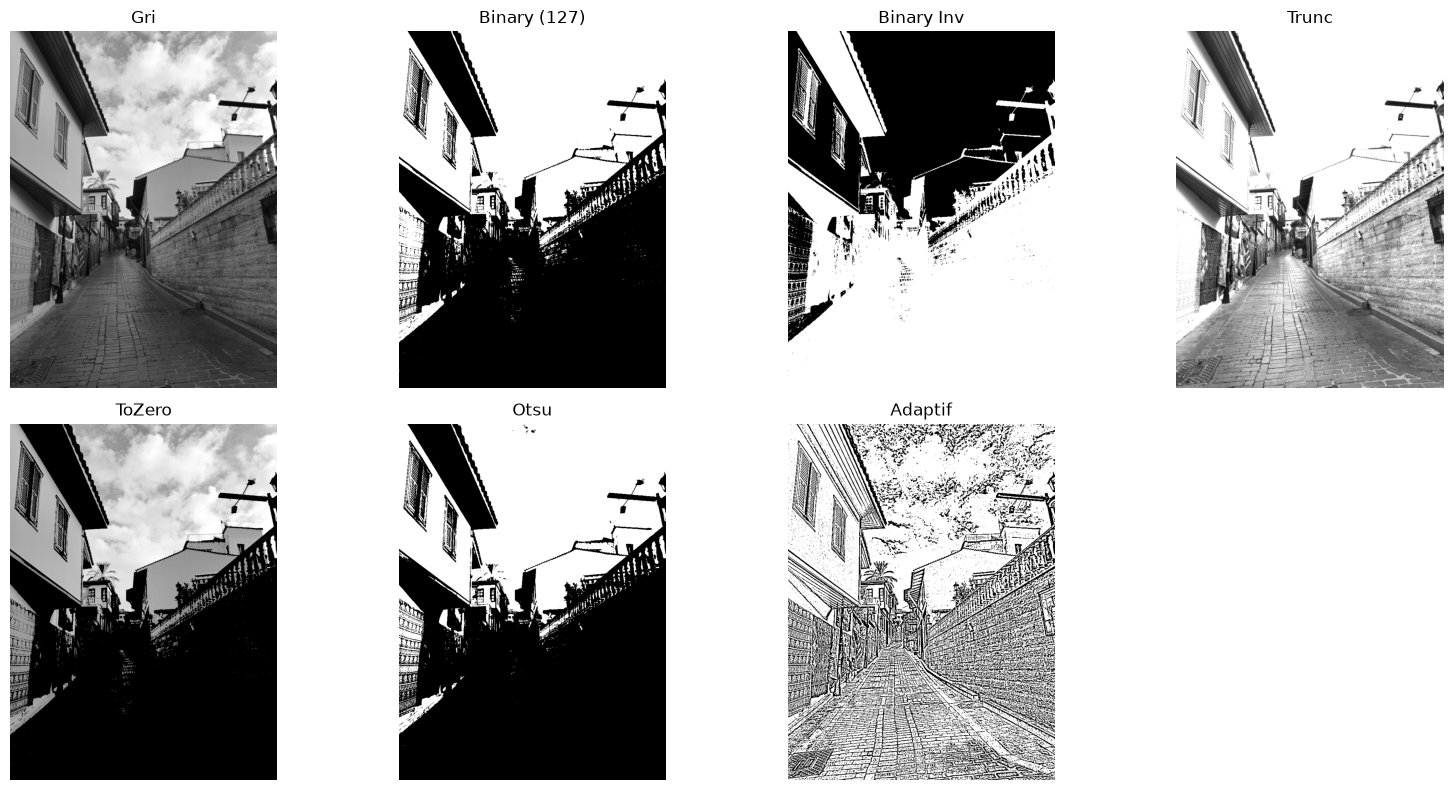

In [10]:
_, bin_127 = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)
_, bin_inv = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY_INV)
_, trunc = cv2.threshold(img_gray, 127, 255, cv2.THRESH_TRUNC)
_, tozero = cv2.threshold(img_gray, 127, 255, cv2.THRESH_TOZERO)
otsu_esik, otsu = cv2.threshold(img_gray, 0, 255,
                                cv2.THRESH_BINARY + cv2.THRESH_OTSU)
adaptif = cv2.adaptiveThreshold(img_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                cv2.THRESH_BINARY, 11, 2)

print("Otsu'nun bulduğu eşik değeri:", otsu_esik)
goster([img_gray, bin_127, bin_inv, trunc, tozero, otsu, adaptif],
       ["Gri", "Binary (127)", "Binary Inv", "Trunc", "ToZero",
        "Otsu", "Adaptif"], satir=2)

## 8) K-means ile görüntü segmentasyonu

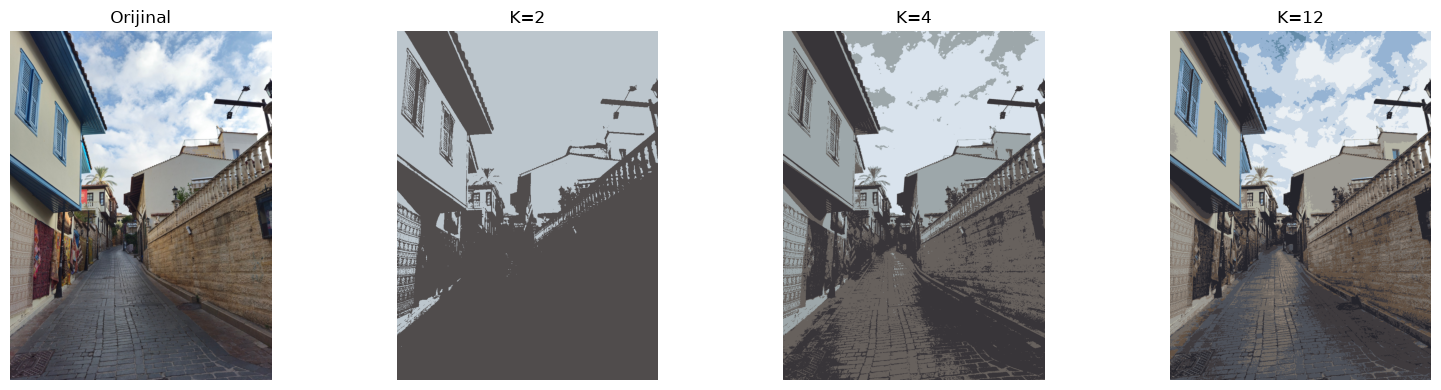

In [11]:
def kmeans_segmentasyon(goruntu, k):
    veri = goruntu.reshape((-1, 3)).astype(np.float32)
    kriter = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 1.0)
    _, etiket, merkez = cv2.kmeans(veri, k, None, kriter, 10,
                                   cv2.KMEANS_RANDOM_CENTERS)
    merkez = np.uint8(merkez)
    return merkez[etiket.flatten()].reshape(goruntu.shape), etiket.reshape(goruntu.shape[:2])

seg2, _ = kmeans_segmentasyon(img_bgr, 2)
seg4, _ = kmeans_segmentasyon(img_bgr, 4)
seg8, _ = kmeans_segmentasyon(img_bgr,12)
goster([img_bgr, seg2, seg4, seg8], ["Orijinal", "K=2", "K=4", "K=12"])

## 8b) Bölge büyütme (Region Growing)

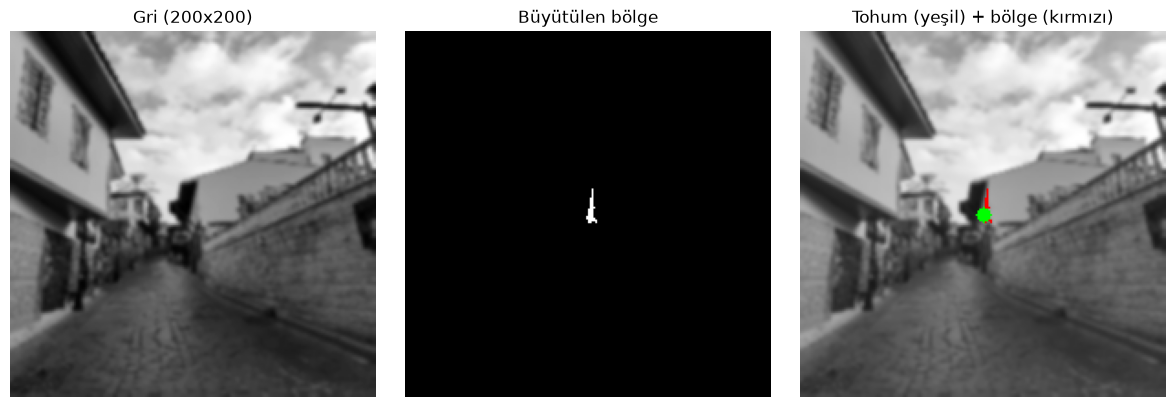

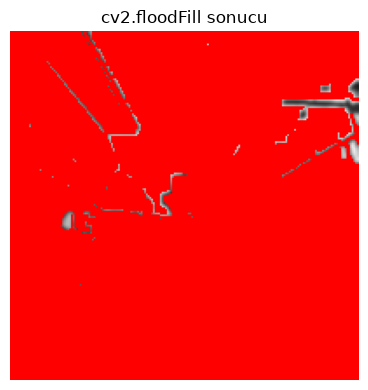

In [12]:
def bolge_buyutme(gri, tohum, esik=15):
    """Tohum pikselden başlayarak, parlaklığı tohuma 'esik' kadar yakın komşuları ekler."""
    yuk, gen = gri.shape
    maske = np.zeros((yuk, gen), np.uint8)
    tohum_deger = int(gri[tohum[1], tohum[0]])
    yigin = [tohum]
    while yigin:
        x, y = yigin.pop()
        if maske[y, x]:
            continue
        if abs(int(gri[y, x]) - tohum_deger) > esik:
            continue
        maske[y, x] = 255
        for dx, dy in ((1, 0), (-1, 0), (0, 1), (0, -1)):
            nx, ny = x + dx, y + dy
            if 0 <= nx < gen and 0 <= ny < yuk and not maske[ny, nx]:
                yigin.append((nx, ny))
    return maske

kucuk_gri = cv2.resize(img_gray, (200, 200))               # hız için küçült
kucuk_gri = cv2.GaussianBlur(kucuk_gri, (5, 5), 0)
tohum = (100, 100)                                          # (x, y) -> değiştirebilirsin
bolge = bolge_buyutme(kucuk_gri, tohum, esik=15)

isaret = cv2.cvtColor(kucuk_gri, cv2.COLOR_GRAY2BGR)
isaret[bolge == 255] = (0, 0, 255)
cv2.circle(isaret, tohum, 4, (0, 255, 0), -1)
goster([kucuk_gri, bolge, isaret],
       ["Gri (200x200)", "Büyütülen bölge", "Tohum (yeşil) + bölge (kırmızı)"])

# Alternatif: OpenCV'nin hazır floodFill fonksiyonu
ff = cv2.cvtColor(kucuk_gri, cv2.COLOR_GRAY2BGR)
ff_maske = np.zeros((202, 202), np.uint8)
cv2.floodFill(ff, ff_maske, tohum, (0, 0, 255), (15,) * 3, (15,) * 3)
goster([ff], ["cv2.floodFill sonucu"])

## 9) Morfolojik işlemler: Erosion, Dilation, Opening, Closing

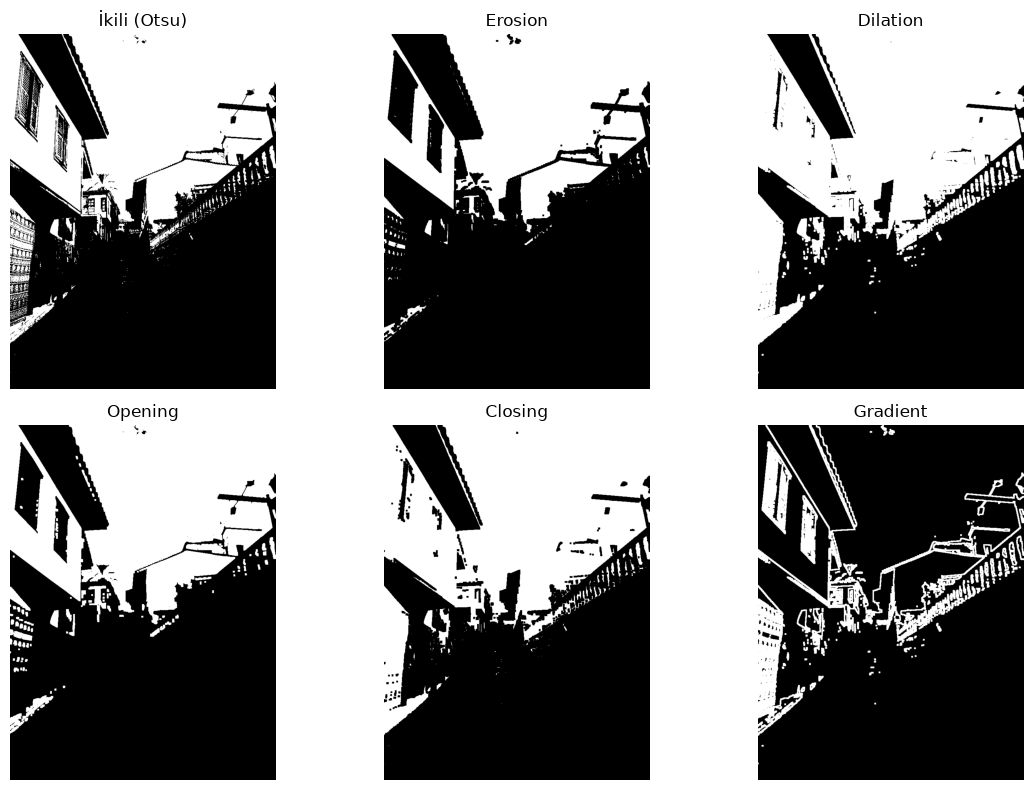

In [13]:
_, ikili = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

erosion = cv2.erode(ikili, kernel, iterations=1)       # aşındırma
dilation = cv2.dilate(ikili, kernel, iterations=1)     # genişletme
opening = cv2.morphologyEx(ikili, cv2.MORPH_OPEN, kernel)    # açma  = erosion -> dilation
closing = cv2.morphologyEx(ikili, cv2.MORPH_CLOSE, kernel)   # kapama = dilation -> erosion
gradyan = cv2.morphologyEx(ikili, cv2.MORPH_GRADIENT, kernel)  # bonus: kenar çizgisi

goster([ikili, erosion, dilation, opening, closing, gradyan],
       ["İkili (Otsu)", "Erosion", "Dilation", "Opening", "Closing", "Gradient"],
       satir=2)

## 9b) Parmak izi temizleme - morfolojinin gücü

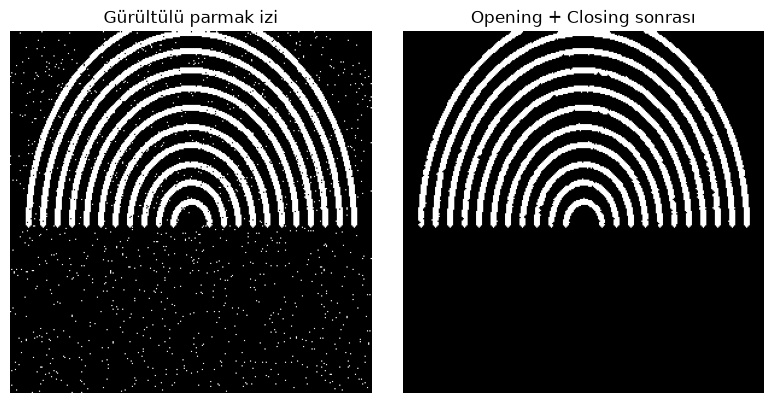

In [14]:
# Gerçek parmak izi görselin varsa yolunu yaz. Yoksa sentetik gürültülü örnek üretilir.
PARMAK_IZI_YOLU = "parmak_izi.png"

if os.path.exists(PARMAK_IZI_YOLU):
    pi = cv2.imread(PARMAK_IZI_YOLU, cv2.IMREAD_GRAYSCALE)
    _, pi_ikili = cv2.threshold(pi, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
else:
    # Sentetik "parmak izi": eş merkezli eğriler + tuz-biber gürültüsü + boşluklar
    pi_ikili = np.zeros((300, 300), np.uint8)
    for r in range(15, 140, 12):
        cv2.ellipse(pi_ikili, (150, 160), (r, int(r * 1.3)), 0, 180, 360, 255, 3)
    rng = np.random.default_rng(0)
    gurultu = rng.random(pi_ikili.shape)
    pi_ikili[gurultu > 0.985] = 255   # beyaz benekler (tuz)
    pi_ikili[gurultu < 0.015] = 0     # siyah delikler (biber)

k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
temiz = cv2.morphologyEx(pi_ikili, cv2.MORPH_OPEN, k)   # küçük beyaz gürültüyü siler
temiz = cv2.morphologyEx(temiz, cv2.MORPH_CLOSE, k)     # çizgilerdeki boşlukları kapatır

goster([pi_ikili, temiz], ["Gürültülü parmak izi", "Opening + Closing sonrası"])

## 10) Şekil analizi (kontur, alan, çevre, yaklaşım, çember benzerliği)

Elips/Diger  alan= 15708.0 cevre=  511.0 köşe=8 dairesellik=0.76
Ucgen        alan=  7200.0 cevre=  409.7 köşe=3 dairesellik=0.54
Daire        alan= 11120.0 cevre=  395.6 köşe=8 dairesellik=0.89
Dortgen      alan= 18000.0 cevre=  540.0 köşe=4 dairesellik=0.78


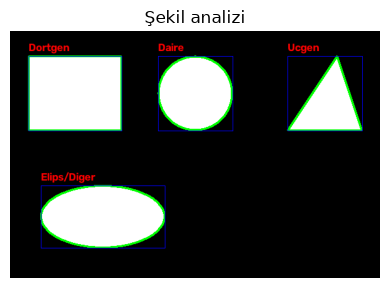

In [15]:
# Test için basit şekiller çizelim
sekiller = np.zeros((400, 600), np.uint8)
cv2.rectangle(sekiller, (30, 40), (180, 160), 255, -1)           # dikdörtgen
cv2.circle(sekiller, (300, 100), 60, 255, -1)                     # daire
cv2.fillPoly(sekiller, [np.array([[450, 160], [530, 40], [570, 160]])], 255)  # üçgen
cv2.ellipse(sekiller, (150, 300), (100, 50), 0, 0, 360, 255, -1)  # elips

konturlar, _ = cv2.findContours(sekiller, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cikti = cv2.cvtColor(sekiller, cv2.COLOR_GRAY2BGR)

for c in konturlar:
    alan = cv2.contourArea(c)
    cevre = cv2.arcLength(c, True)
    yaklasik = cv2.approxPolyDP(c, 0.03 * cevre, True)
    kose = len(yaklasik)
    daire_benzerligi = 4 * np.pi * alan / (cevre ** 2)   # 1'e yakınsa daire
    x, y, w, h = cv2.boundingRect(c)

    if kose == 3:
        ad = "Ucgen"
    elif kose == 4:
        ad = "Dortgen"
    elif daire_benzerligi > 0.85:
        ad = "Daire"
    else:
        ad = "Elips/Diger"

    cv2.drawContours(cikti, [c], -1, (0, 255, 0), 2)
    cv2.rectangle(cikti, (x, y), (x + w, y + h), (255, 0, 0), 1)
    cv2.putText(cikti, ad, (x, y - 8), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)
    print(f"{ad:12s} alan={alan:8.1f} cevre={cevre:7.1f} köşe={kose} "
          f"dairesellik={daire_benzerligi:.2f}")

goster([cikti], ["Şekil analizi"])

## 11) Iris Dataset'ini yükleme ve inceleme

Boyut: (150, 5)

İlk 5 satır:
    sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

      tur  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

İstatistikler:
        sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%            

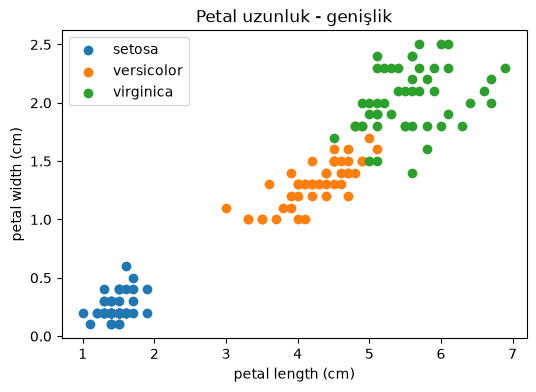

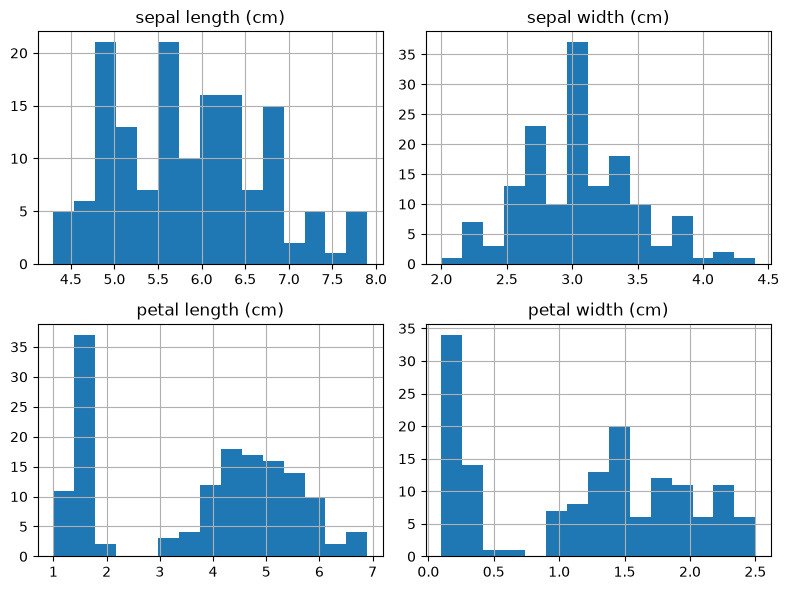

In [16]:
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["tur"] = pd.Categorical.from_codes(iris.target, iris.target_names)

print("Boyut:", df.shape)
print("\nİlk 5 satır:\n", df.head())
print("\nİstatistikler:\n", df.describe())
print("\nSınıf dağılımı:\n", df["tur"].value_counts())
print("\nEksik veri:\n", df.isnull().sum())

# Görselleştirme: dağılım grafiği + histogramlar
renkler = {"setosa": "tab:blue", "versicolor": "tab:orange", "virginica": "tab:green"}
plt.figure(figsize=(6, 4))
for tur, grup in df.groupby("tur", observed=True):
    plt.scatter(grup.iloc[:, 2], grup.iloc[:, 3], label=tur, c=renkler[tur])
plt.xlabel(iris.feature_names[2]); plt.ylabel(iris.feature_names[3])
plt.legend(); plt.title("Petal uzunluk - genişlik"); plt.show()

df.iloc[:, :4].hist(bins=15, figsize=(8, 6))
plt.tight_layout(); plt.show()

## 12) Aktif Kontur (Active Contour / Snake) yöntemi

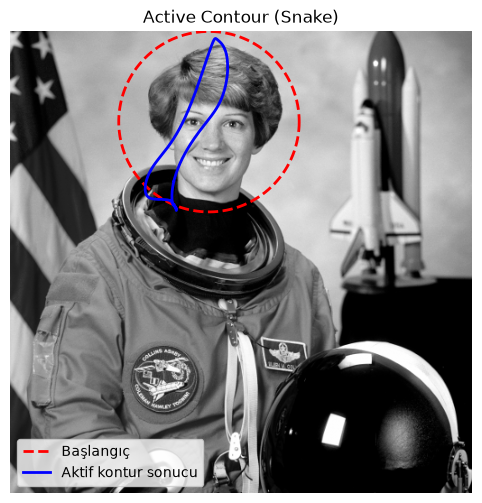

Bitti! Tüm başlıklar çalıştırıldı.


In [17]:
from skimage.segmentation import active_contour
from skimage.filters import gaussian
from skimage import data, color

astro = data.astronaut()
astro_gri = color.rgb2gray(astro)

# Başlangıç konturu: yüz çevresinde bir çember
s = np.linspace(0, 2 * np.pi, 400)
x = 220 + 100 * np.cos(s)
y = 100 + 100 * np.sin(s)
baslangic = np.array([x, y]).T

snake = active_contour(gaussian(astro_gri, sigma=3, preserve_range=False),
                       baslangic, alpha=0.015, beta=10, gamma=0.001)

plt.figure(figsize=(6, 6))
plt.imshow(astro_gri, cmap="gray")
plt.plot(baslangic[:, 0], baslangic[:, 1], "--r", lw=2, label="Başlangıç")
plt.plot(snake[:, 0], snake[:, 1], "-b", lw=2, label="Aktif kontur sonucu")
plt.legend(); plt.axis("off"); plt.title("Active Contour (Snake)")
plt.show()

print("Bitti! Tüm başlıklar çalıştırıldı.")